# 01 · Data understanding

**Goal:** detect 12 knee abnormalities (macro ROC-AUC) from multi-series knee MRI.

What makes this problem unusual:

| | |
|---|---|
| Training studies | 4,407 MRI studies, up to 6 series each (sagittal / coronal / axial × fluid-sensitive or not) |
| Image labels | only **58** studies have radiologist labels read from the images ("gold") |
| Everything else | a free-text radiology **report** in about ten languages |
| Test set | about 1,300 hidden studies, **images only** (no report) |

So training labels have to be extracted from the reports, and the 58 gold studies are kept for validation only.
This notebook profiles the reports and the gold labels (the DICOM images are processed on Kaggle; see notebook 03).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kneemri.constants import LABELS
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MET = ROOT / "reports" / "metrics"; MET.mkdir(parents=True, exist_ok=True)

In [2]:
train = pd.read_csv(ROOT / "data" / "train.csv")
is_gold = train[LABELS].notna().all(axis=1)
print(f"studies: {len(train):,} | gold (image-labelled): {is_gold.sum()} | report-only: {(~is_gold).sum():,}")
print("columns:", list(train.columns))

studies: 4,407 | gold (image-labelled): 58 | report-only: 4,349
columns: ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


## Reports: languages and length
Language is estimated with a light stop-word heuristic (good enough to show the mix; it is not used by the models).

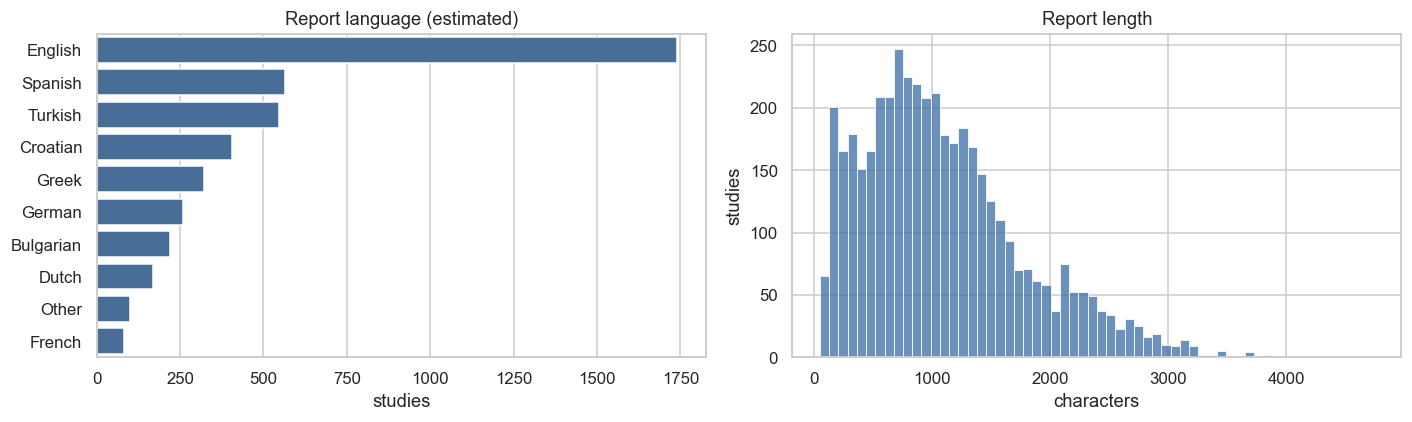

count    4407.0
mean     1098.0
std       694.0
min        52.0
25%       588.0
50%       977.0
75%      1460.0
max      4743.0


In [3]:
import re
MARKERS = {
    "English": [" the ", " of ", " and ", " with ", " no "], "German": [" der ", " und ", " die ", " kein", " mit "],
    "Spanish": [" del ", " con ", " sin ", " los ", " rotura"], "Portuguese": [" com ", " sem ", " não ", " do ", " da "],
    "Italian": [" della ", " con ", " non ", " il ", " alla "], "French": [" des ", " avec ", " pas ", " du ", " le "],
    "Dutch": [" het ", " van ", " geen ", " een ", " en "], "Turkish": [" ve ", " izlen", " mevcut", " saptan", " bulgu"],
    "Croatian": [" je ", " bez ", " te ", " na ", " su "],
}
def language(text):
    t = str(text)
    if re.search("[\u0370-\u03ff]", t): return "Greek"
    if re.search("[\u0400-\u04ff]", t): return "Bulgarian"
    if re.search("[\u4e00-\u9fff]", t): return "Chinese"
    low = " " + t.lower() + " "
    score = {k: sum(low.count(w) for w in v) for k, v in MARKERS.items()}
    best = max(score, key=score.get)
    return best if score[best] else "Other"

train["language"] = train.Report.map(language)
train["report_chars"] = train.Report.str.len()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
vc = train.language.value_counts()
sns.barplot(x=vc.values, y=vc.index, ax=ax[0], color="#3b6ea5")
ax[0].set(title="Report language (estimated)", xlabel="studies", ylabel="")
sns.histplot(train.report_chars, bins=60, ax=ax[1], color="#3b6ea5")
ax[1].set(title="Report length", xlabel="characters", ylabel="studies")
plt.tight_layout(); plt.savefig(FIG / "01_reports.png"); plt.show()
print(train.report_chars.describe().round(0).to_string())

## Gold labels
The 58 gold studies are labelled from the images with a low threshold, so prevalence is high
(effusion, synovitis and meniscus tears in roughly half of them). Report wording often under-reports these.

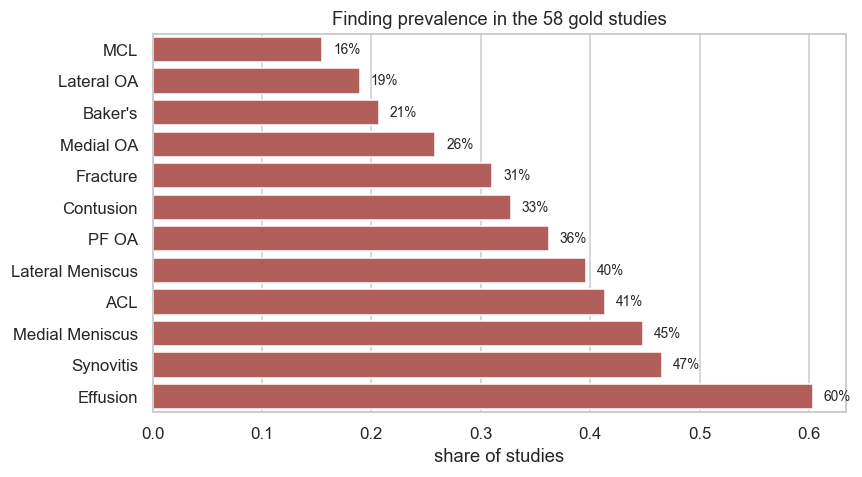

In [4]:
gold = train[is_gold]
prev = gold[LABELS].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=prev.values, y=prev.index, ax=ax, color="#c0504d")
ax.set(title="Finding prevalence in the 58 gold studies", xlabel="share of studies", ylabel="")
for i, v in enumerate(prev.values): ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "01_gold_prevalence.png"); plt.show()

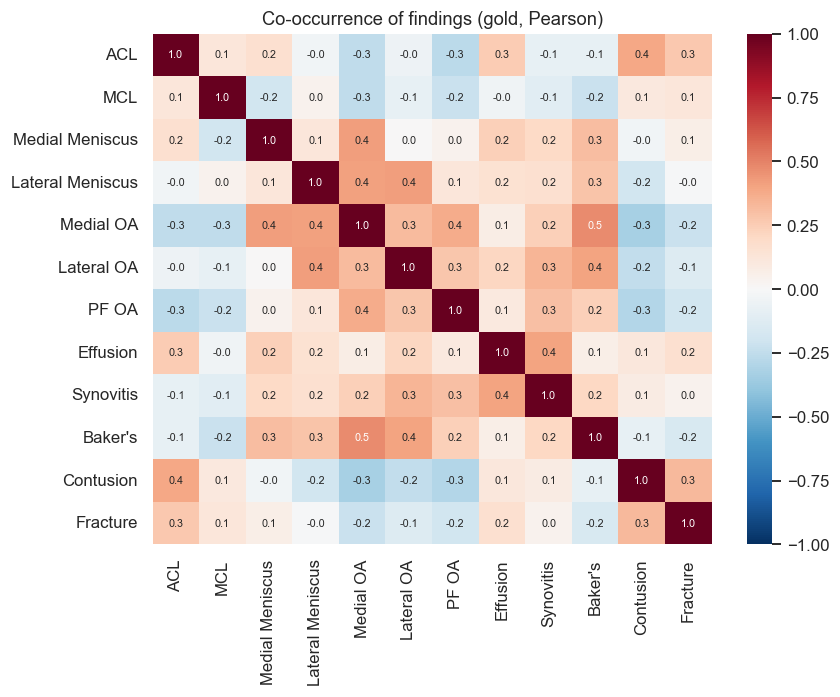

In [5]:
co = gold[LABELS].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(co, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Co-occurrence of findings (gold, Pearson)")
plt.tight_layout(); plt.savefig(FIG / "01_gold_cooccurrence.png"); plt.show()

**Takeaways**
* The labels are the bottleneck: 4,349 of 4,407 training studies have only a multilingual report.
* Gold is too small to train on and noisy as a validation set (±0.005 macro AUC is noise), so it is used for
  validation, label calibration and label-source weighting only.
* Findings co-occur (meniscus tears with OA, effusion with synovitis), which a shared multi-label model can exploit.